### AmExpert 2019

### Description of the dataset

The data available in this problem contains the following information, including the details of a sample of campaigns and coupons used in previous campaigns -

User Demographic Details
Campaign and coupon Details
Product details
Previous transactions
Based on previous transaction & performance data from the last 18 campaigns, predict the probability for the next 10 campaigns in the test set for each coupon and customer combination, whether the customer will redeem the coupon or not?

In [1]:


import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
campaign_data = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/campaign_data.csv")
coupon_item_mapping = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/coupon_item_mapping.csv")
customer_demographics = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/customer_demographics.csv")
customer_transaction_data = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/customer_transaction_data.csv")
item_data = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/item_data.csv")
train = pd.read_csv("/Users/Usuario/Documents/Proyectos-GitHub/Series temporales/Src/dataset/train.csv")




In [3]:
customer_transaction_data

,date,customer_id,item_id,quantity,selling_price,other_discount,coupon_discount
0,2012-01-02,1501,26830,1,35.26,-10.69,0.0
1,2012-01-02,1501,54253,1,53.43,-13.89,0.0
2,2012-01-02,1501,31962,1,106.50,-14.25,0.0
3,2012-01-02,1501,33647,1,67.32,0.00,0.0
4,2012-01-02,1501,48199,1,71.24,-28.14,0.0
...,...,...,...,...,...,...,...
1324561,2013-06-30,1129,2777,1,284.60,-71.24,0.0
1324562,2013-06-30,1129,2953,4,42.74,-28.50,0.0
1324563,2013-06-30,1129,2971,6,64.12,-42.74,0.0
1324564,2013-06-30,1129,46984,1,95.82,0.00,0.0


### Ventas totales por día

In [4]:
salesxday = (customer_transaction_data.groupby('date').agg({'selling_price': 'sum'}).reset_index().rename(columns={'selling_price': 'total_sales'}))

In [5]:
salesxday
salesxday['date'] = pd.to_datetime(salesxday['date'])

### Entender evolución temporal, tendencia, estacionalidad, ruido y anomalías.

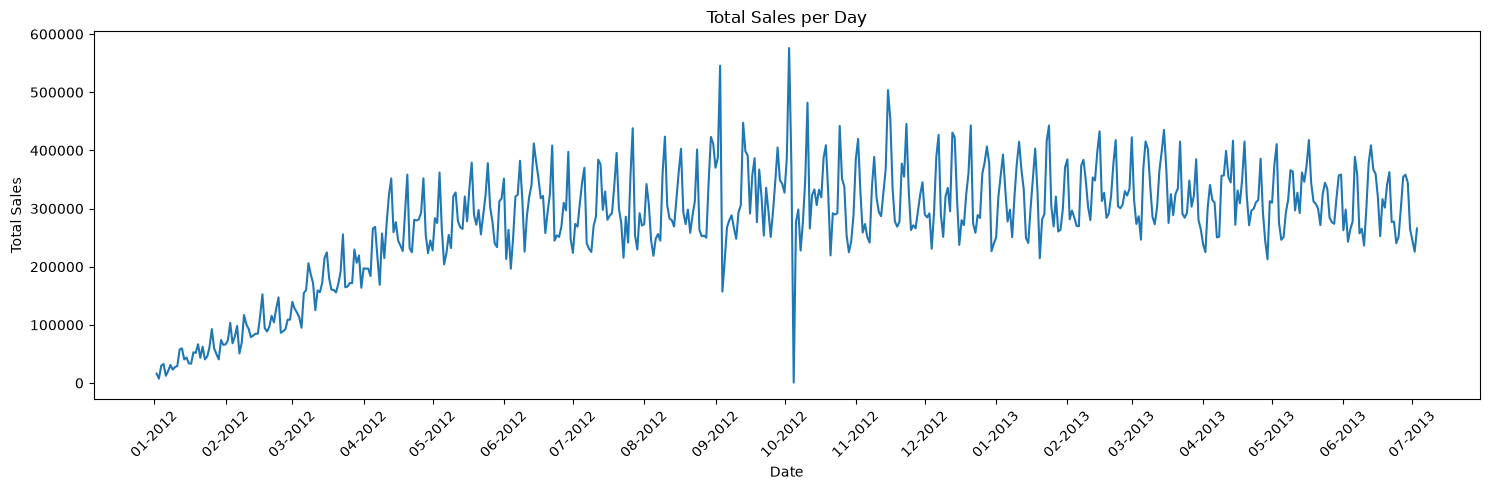

In [6]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(15, 5))

plt.plot(
    salesxday['date'],
    salesxday['total_sales']
)

plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Total Sales per Day')

ax = plt.gca()

# Una marca por mes
ax.xaxis.set_major_locator(mdates.MonthLocator())

# Mostrar mes y año
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%Y'))

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Pre procesamiento

In [7]:
salesxday['date'] = pd.to_datetime(salesxday['date'])

full_dates = pd.date_range(
    start=salesxday['date'].min(),
    end=salesxday['date'].max(),
    freq='D'
)

missing_dates = full_dates.difference(salesxday['date'])

print("Días faltantes:", len(missing_dates))
print(missing_dates)

Días faltantes: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


### Análisis Descriptivo

Resumen de resultados del Análisis exploratorio y resultados de estacionalidad y autocorrelación.

#### Moving Average

In [8]:
salesxday['MA_7'] = (
    salesxday['total_sales']
    .rolling(7)
    .mean()
)

salesxday['MA_30'] = (
    salesxday['total_sales']
    .rolling(30)
    .mean()
)

salesxday['MA_90'] = salesxday['total_sales'].rolling(window=90).mean()

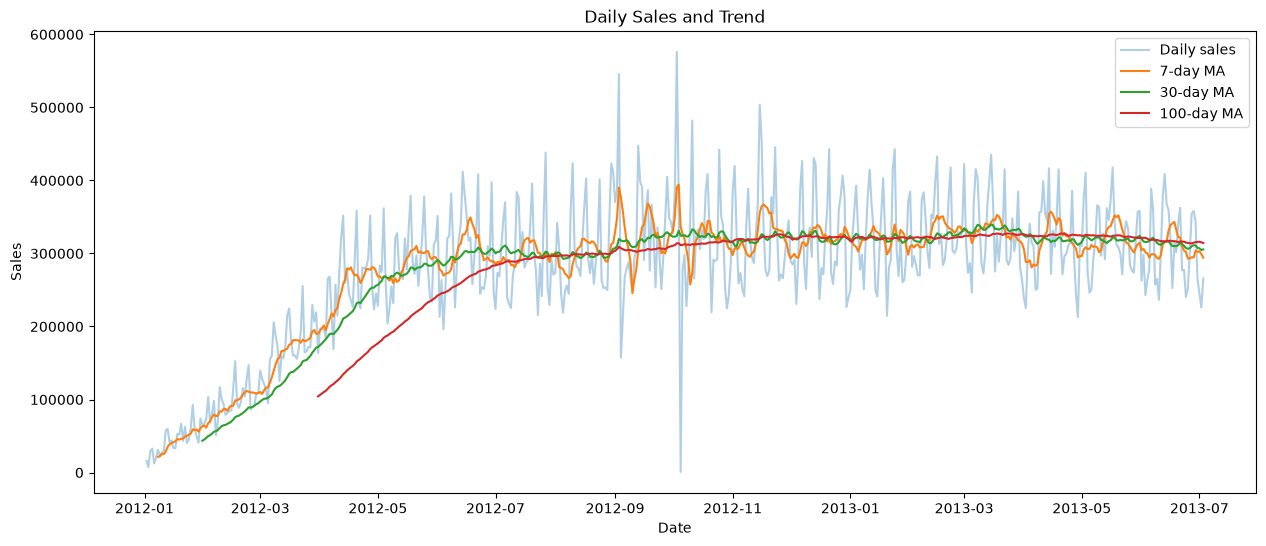

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(
    salesxday['date'],
    salesxday['total_sales'],
    alpha=0.35,
    label='Daily sales'
)

plt.plot(
    salesxday['date'],
    salesxday['MA_7'],
    label='7-day MA'
)

plt.plot(
    salesxday['date'],
    salesxday['MA_30'],
    label='30-day MA'
)
plt.plot(
    salesxday['date'],
    salesxday['MA_90'],
    label='100-day MA'
)

plt.legend()
plt.title('Daily Sales and Trend')
plt.xlabel('Date')
plt.ylabel('Sales')

plt.show()


A través de las medias móviles: Vemos como comienza la serie de modo creciente hasta julio-agosto del 2012 y luego se reduce la pendiente hasta casi cero, manteniendose estable, hasta 05-2013, donde si bien es muy leve, comienza a decrecer.

#### Estacionalidad semanal

In [10]:
# Creamos el día de la semana
salesxday['day_of_week'] = salesxday['date'].dt.day_name()

In [11]:
salesxday

,date,total_sales,MA_7,MA_30,MA_90,day_of_week
0,2012-01-02,16167.78,NaN,NaN,NaN,Monday
1,2012-01-03,7507.62,NaN,NaN,NaN,Tuesday
2,2012-01-04,29756.39,NaN,NaN,NaN,Wednesday
3,2012-01-05,32775.15,NaN,NaN,NaN,Thursday
4,2012-01-06,12550.96,NaN,NaN,NaN,Friday
...,...,...,...,...,...,...
544,2013-06-29,344459.44,304010.500000,310830.241000,315558.440444,Saturday
545,2013-06-30,264831.94,302178.578571,307709.526000,315849.876222,Sunday
546,2013-07-01,245775.92,302941.950000,307145.437333,316079.898778,Monday
547,2013-07-02,225848.73,299252.064286,304731.132333,315240.039000,Tuesday


In [12]:
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

sales_by_dow = (
    salesxday
    .groupby('day_of_week')['total_sales']
    .agg(['mean', 'median', 'std'])
    .reindex(days_order)
)

sales_by_dow

,mean,median,std
day_of_week,,,
Monday,243084.109873,260473.270,83952.837422
Tuesday,248284.622911,265996.710,83806.072726
Wednesday,274356.790380,295307.960,93729.556133
Thursday,321570.356538,346181.370,101457.317401
Friday,335014.902821,377191.905,111869.541459
Saturday,268047.281410,289283.870,87243.492026
Sunday,245979.758846,265013.175,79765.849421


mean   → promedio, sensible a outliers
median → día "típico", robusto a outliers
std    → cuánto varían las ventas

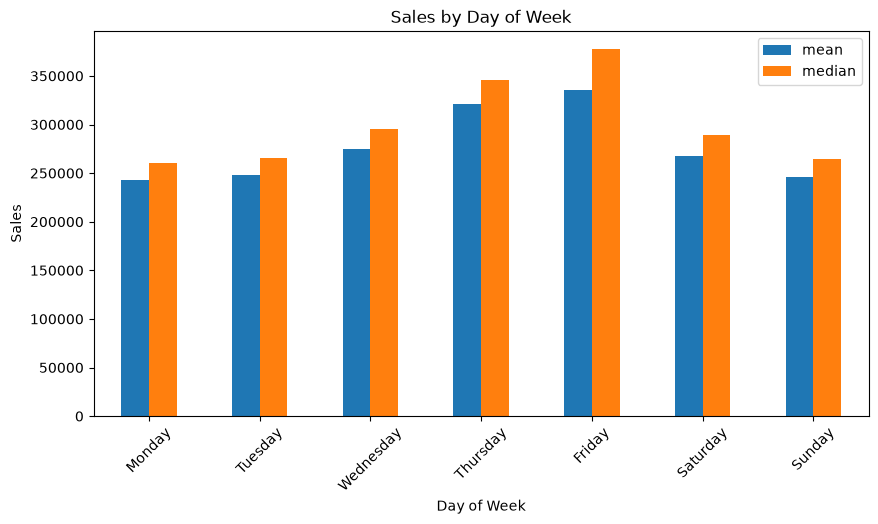

In [13]:
sales_by_dow[['mean', 'median']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Sales by Day of Week')
plt.ylabel('Sales')
plt.xlabel('Day of Week')
plt.xticks(rotation=45)
plt.show()

Existe una estacionalidad semanal consistente (Tiende a repetirse cada 7 días), con mayor nivel de ventas hacia el jueves y viernes.

### ¿Y cambia ese patrón según el período?

In [14]:
salesxday['year_month'] = salesxday['date'].dt.to_period('M')
salesxday['day_of_week'] = salesxday['date'].dt.day_name()

In [15]:
salesxday


,date,total_sales,MA_7,MA_30,MA_90,day_of_week,year_month
0,2012-01-02,16167.78,NaN,NaN,NaN,Monday,2012-01
1,2012-01-03,7507.62,NaN,NaN,NaN,Tuesday,2012-01
2,2012-01-04,29756.39,NaN,NaN,NaN,Wednesday,2012-01
3,2012-01-05,32775.15,NaN,NaN,NaN,Thursday,2012-01
4,2012-01-06,12550.96,NaN,NaN,NaN,Friday,2012-01
...,...,...,...,...,...,...,...
544,2013-06-29,344459.44,304010.500000,310830.241000,315558.440444,Saturday,2013-06
545,2013-06-30,264831.94,302178.578571,307709.526000,315849.876222,Sunday,2013-06
546,2013-07-01,245775.92,302941.950000,307145.437333,316079.898778,Monday,2013-07
547,2013-07-02,225848.73,299252.064286,304731.132333,315240.039000,Tuesday,2013-07


In [16]:
dow_month = salesxday.pivot_table(
    index='year_month',
    columns='day_of_week',
    values='total_sales',
    aggfunc='mean'
)

dow_month = dow_month.reindex(columns=days_order)

dow_month

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
year_month,,,,,,,
2012-01,37492.0400,35873.8480,43455.5725,58717.2175,49721.7550,38573.2725,44547.5575
2012-02,92208.3250,90148.2900,86805.4880,108411.3100,126083.0125,85585.1425,84137.9750
2012-03,146627.3575,159600.3050,183056.4500,191860.5160,202964.9940,160424.3140,141224.4725
2012-04,244956.5400,231872.4725,241744.1450,293798.0275,332665.3425,240595.3875,218248.5420
2012-05,256430.1650,258600.7920,279003.5180,314379.1700,361654.5125,283535.6475,255454.1625
2012-06,264308.7450,274174.8675,316260.0725,339419.1325,383978.1860,274743.6420,265257.0700
2012-07,257452.3940,276686.9400,282141.5250,355834.4275,395077.2425,272964.9625,257907.6260
2012-08,269930.7550,258369.2900,293489.9920,360305.6200,389447.0920,277057.7925,256767.5050
2012-09,361814.4875,272198.8325,271879.0475,357506.2500,350925.6225,330359.6280,324700.1560


In [17]:
monthly_dow = (
    salesxday
    .groupby(['year_month', 'day_of_week'])['total_sales']
    .mean()
    .reset_index(name='avg_sales')
)

In [18]:
salesxday

,date,total_sales,MA_7,MA_30,MA_90,day_of_week,year_month
0,2012-01-02,16167.78,NaN,NaN,NaN,Monday,2012-01
1,2012-01-03,7507.62,NaN,NaN,NaN,Tuesday,2012-01
2,2012-01-04,29756.39,NaN,NaN,NaN,Wednesday,2012-01
3,2012-01-05,32775.15,NaN,NaN,NaN,Thursday,2012-01
4,2012-01-06,12550.96,NaN,NaN,NaN,Friday,2012-01
...,...,...,...,...,...,...,...
544,2013-06-29,344459.44,304010.500000,310830.241000,315558.440444,Saturday,2013-06
545,2013-06-30,264831.94,302178.578571,307709.526000,315849.876222,Sunday,2013-06
546,2013-07-01,245775.92,302941.950000,307145.437333,316079.898778,Monday,2013-07
547,2013-07-02,225848.73,299252.064286,304731.132333,315240.039000,Tuesday,2013-07


In [19]:
monthly_avg = (
    salesxday
    .groupby('year_month')['total_sales']
    .mean()
    .reset_index(name='monthly_avg')
)


monthly_dow = monthly_dow.merge(
    monthly_avg,
    on='year_month'
)



In [20]:
monthly_dow['seasonal_index'] = (
    monthly_dow['avg_sales'] /
    monthly_dow['monthly_avg']
)

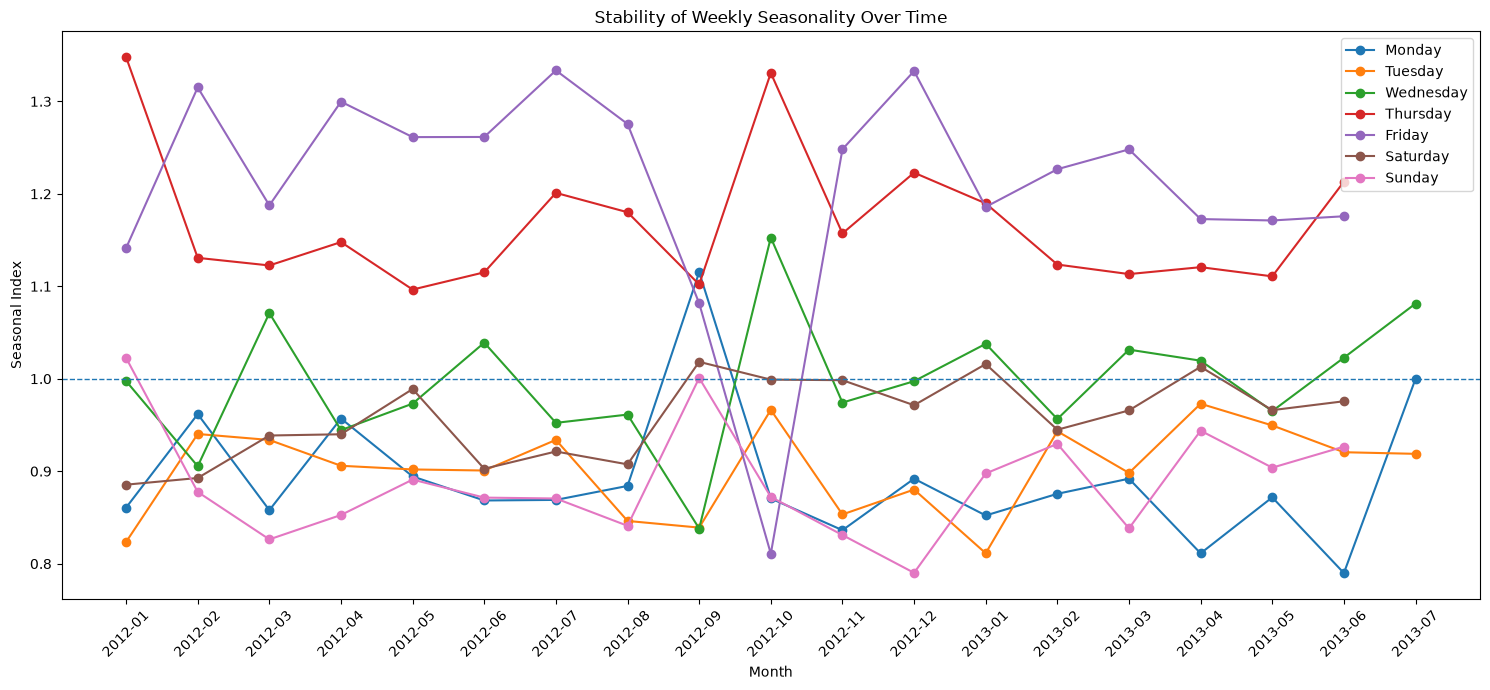

In [21]:


days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]


plt.figure(figsize=(15, 7))

for day in days_order:
    data_day = monthly_dow[
        monthly_dow['day_of_week'] == day
    ]

    plt.plot(
        data_day['year_month'].astype(str),
        data_day['seasonal_index'],
        marker='o',
        label=day
    )

plt.axhline(
    y=1,
    linestyle='--',
    linewidth=1
)

plt.xlabel('Month')
plt.ylabel('Seasonal Index')
plt.title('Stability of Weekly Seasonality Over Time')

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Son de Estacionalidad estable. Cambian muy poco en diferentes meses. Claramente: Friday Thursday and Wednesday son de estacionalidad alta a lo largo de los meses. Excepto en OCT 2012 que algo pasó. Seguidas por Saturday. Y Tusday, sunday and monday que están más pegadas, por debajo del promedio. 

####  Promedio diario mes a mes

In [22]:
salesxday['month'] = salesxday['date'].dt.to_period('M')

sales_month = (
    salesxday
    .groupby('month')
    .agg(
        mean_daily_sales=('total_sales', 'mean'),
        median_daily_sales=('total_sales', 'median'),
        std_daily_sales=('total_sales', 'std')
    )
    .reset_index()
)

sales_month['month'] = sales_month['month'].dt.to_timestamp()

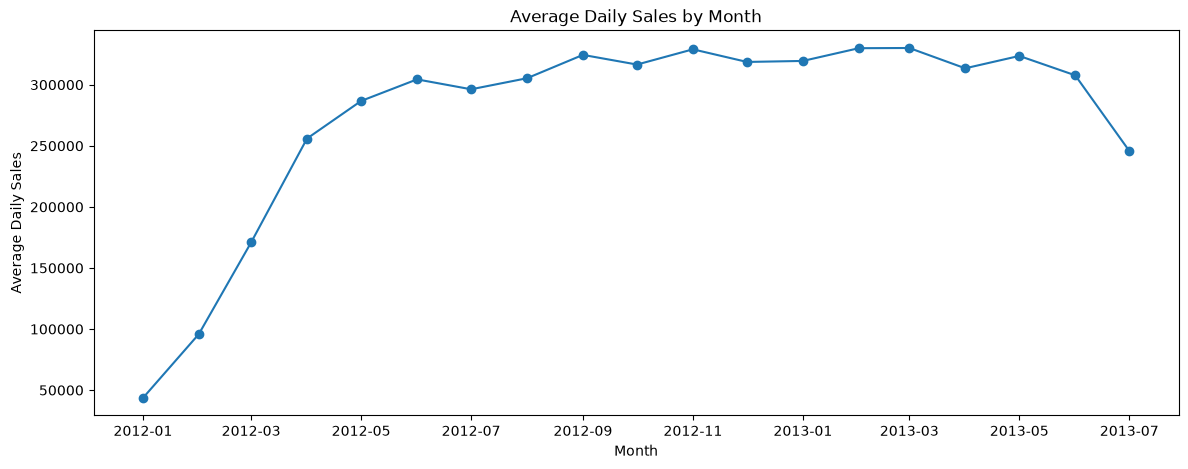

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    sales_month['month'],
    sales_month['mean_daily_sales'],
    marker='o'
)

plt.title('Average Daily Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')

plt.show()

In [24]:
salesxday['year'] = salesxday['date'].dt.year
salesxday['month_num'] = salesxday['date'].dt.month
salesxday['month_name'] = salesxday['date'].dt.month_name()

sales_month_year = (
    salesxday
    .groupby(['year', 'month_num', 'month_name'])
    .agg(total_monthly_sales=('total_sales', 'sum'))
    .reset_index()
)

In [25]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

sales_month_year['month_name'] = pd.Categorical(
    sales_month_year['month_name'],
    categories=month_order,
    ordered=True
)

sales_month_year = sales_month_year.sort_values(
    ['month_num', 'year']
)

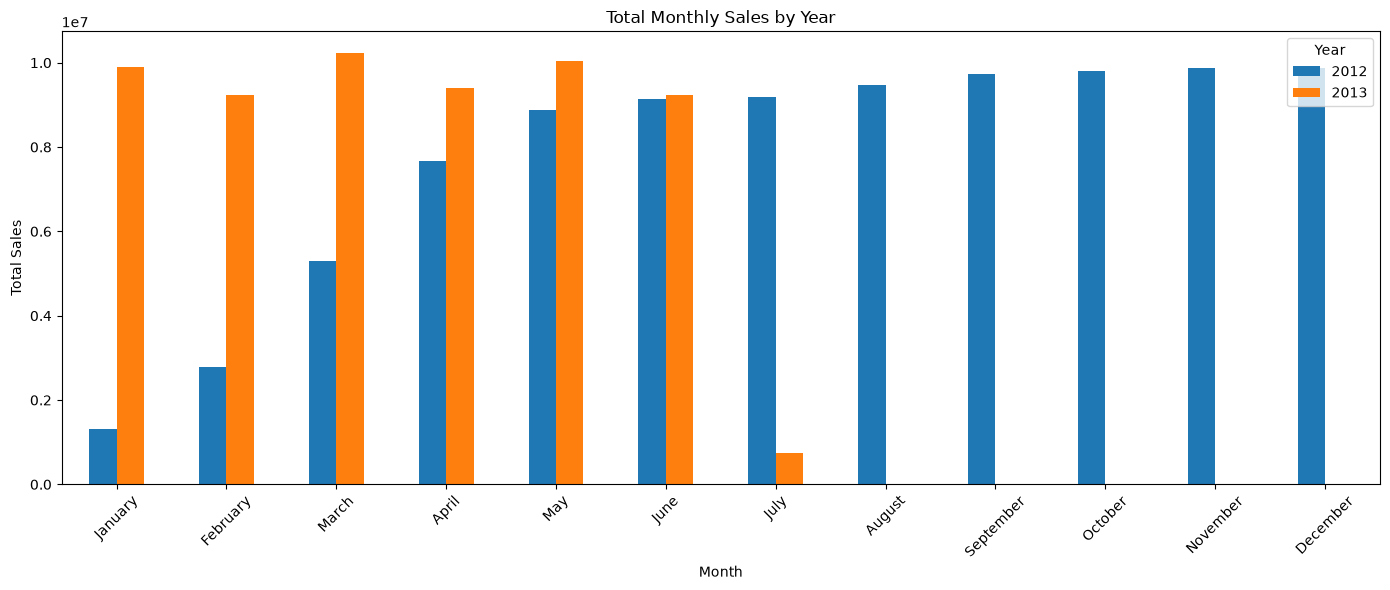

In [26]:
pivot_month = sales_month_year.pivot(
    index='month_name',
    columns='year',
    values='total_monthly_sales'
)

pivot_month.plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Total Monthly Sales by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

Evidencia mensual muy poca para detectar un patrón estacional claro.

##### Variabilidad

dos meses podrían tener el mismo promedio y comportamientos muy distintos

In [27]:
sales_month['cv'] = (
    sales_month['std_daily_sales'] /
    sales_month['mean_daily_sales']
)

In [28]:
sales_month

,month,mean_daily_sales,median_daily_sales,std_daily_sales,cv
0,2012-01-01,43563.031333,42010.320,19558.984691,0.448981
1,2012-02-01,95873.229655,93114.010,22876.170531,0.238609
2,2012-03-01,170912.369677,165968.360,35983.404726,0.210537
3,2012-04-01,255957.563667,255949.795,48993.459961,0.191412
4,2012-05-01,286716.624194,278397.370,44108.613370,0.153840
5,2012-06-01,304376.289667,312454.915,57952.875736,0.190399
6,2012-07-01,296267.981613,286149.690,56416.109425,0.190423
7,2012-08-01,305313.383548,287804.760,59298.181948,0.194221
8,2012-09-01,324419.862667,313007.165,76152.057132,0.234733
9,2012-10-01,316509.458387,319346.200,96470.236929,0.304794


#### Separar formalmente tendencia + estacionalidad + residuo
STL: Seasonal and Trend decomposition using Loess
Separa Trend + Seasional + Residual

In [29]:
serie = (
    salesxday
    .set_index('date')['total_sales']
    .asfreq('D')
)

In [30]:
serie

date
2012-01-02     16167.78
2012-01-03      7507.62
2012-01-04     29756.39
2012-01-05     32775.15
2012-01-06     12550.96
                ...    
2013-06-29    344459.44
2013-06-30    264831.94
2013-07-01    245775.92
2013-07-02    225848.73
2013-07-03    265787.30
Freq: D, Name: total_sales, Length: 549, dtype: float64

In [31]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


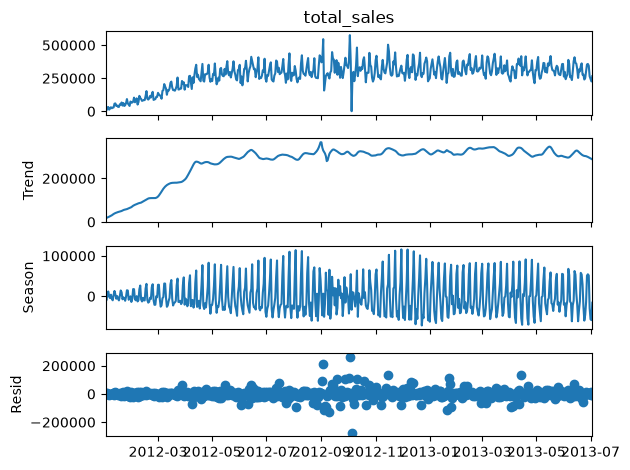

In [35]:
from statsmodels.tsa.seasonal import STL

stl = STL(
    serie,
    period=7,
    robust=True
)

result = stl.fit()

result.plot()
plt.show()

Serie original = Trend + Season + Residuals

#####  Detección de Anomalias.
A partir de Residuals.

In [36]:
resid = result.resid

threshold = 3 * resid.std()

anomalies = resid[
    resid.abs() > threshold
]

anomalies.sort_values()

date
2012-10-05   -273776.404389
2012-09-10   -130539.100927
2012-09-04   -114004.433671
2013-01-20   -112938.413524
2012-10-11    103965.580603
2012-09-18    105638.191037
2013-01-23    109753.031889
2012-10-02    110935.609847
2013-04-14    132406.929935
2012-11-15    135228.547419
2012-09-03    210472.128871
2012-10-03    265474.408260
Name: resid, dtype: float64

In [38]:
salesxday[
    salesxday['date'].isin(anomalies.index)
]

,date,total_sales,MA_7,MA_30,MA_90,day_of_week,year_month,month,year,month_num,month_name
245,2012-09-03,545622.20,390317.432857,319980.864667,308991.803444,Monday,2012-09,2012-09,2012,9,September
246,2012-09-04,157223.98,377080.354286,317929.229333,307176.241000,Tuesday,2012-09,2012-09,2012,9,September
252,2012-09-10,248112.78,245538.194286,308663.647667,303916.346444,Monday,2012-09,2012-09,2012,9,September
260,2012-09-18,386627.63,368247.342857,321663.451333,306077.563556,Tuesday,2012-09,2012-09,2012,9,September
274,2012-10-02,386958.37,350415.732857,322986.180667,311344.228222,Tuesday,2012-10,2012-10,2012,10,October
275,2012-10-03,575966.51,390581.037143,323997.657667,313909.385667,Wednesday,2012-10,2012-10,2012,10,October
277,2012-10-05,801.11,336558.188571,324205.803333,311281.615778,Friday,2012-10,2012-10,2012,10,October
283,2012-10-11,482091.53,273091.990000,333079.658333,312816.560667,Thursday,2012-10,2012-10,2012,10,October
318,2012-11-15,503631.04,355577.221429,321972.737333,320566.671000,Thursday,2012-11,2012-11,2012,11,November
384,2013-01-20,214652.05,298597.660000,315982.793667,320613.701667,Sunday,2013-01,2013-01,2013,1,January


Habría que investigar estos días anomalos. 

#### Distribución de ventas

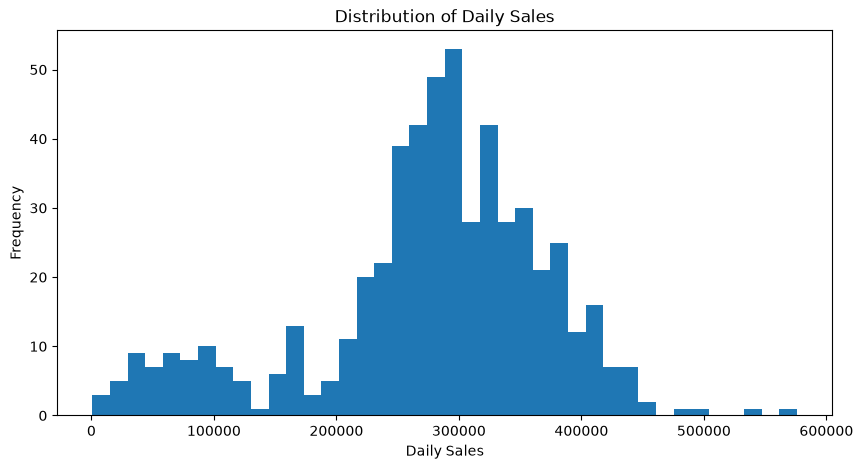

In [39]:
plt.figure(figsize=(10, 5))

plt.hist(
    salesxday['total_sales'],
    bins=40
)

plt.xlabel('Daily Sales')
plt.ylabel('Frequency')
plt.title('Distribution of Daily Sales')

plt.show()

In [40]:
salesxday['total_sales'].describe()

count       549.000000
mean     276502.870128
std       98067.882285
min         801.110000
25%      242835.030000
50%      288694.350000
75%      339822.630000
max      575966.510000
Name: total_sales, dtype: float64

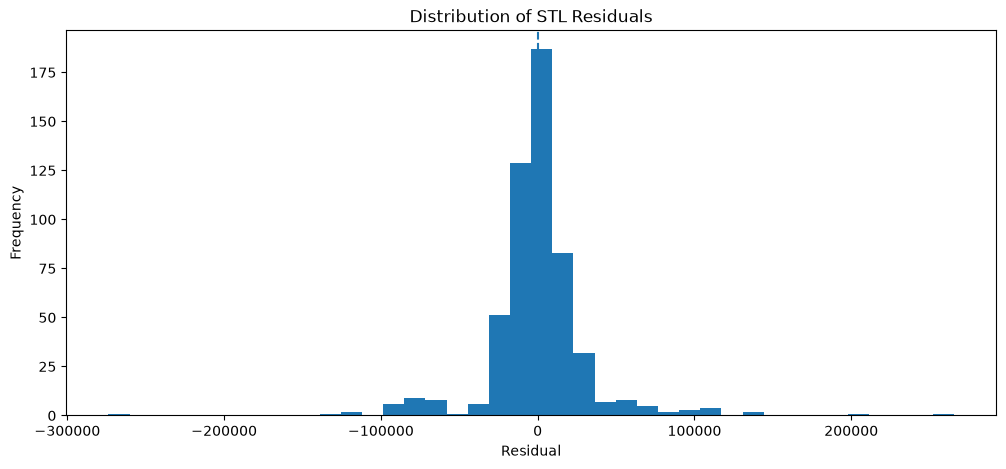

In [41]:
resid = result.resid.dropna()

plt.figure(figsize=(12, 5))
plt.hist(resid, bins=40)

plt.axvline(0, linestyle='--')

plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Distribution of STL Residuals')

plt.show()

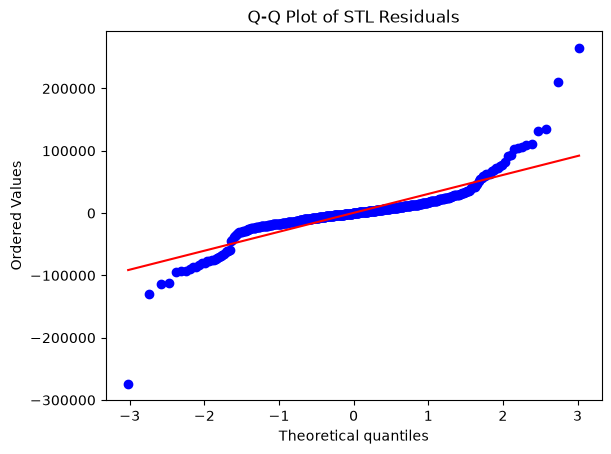

In [42]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(resid, dist="norm", plot=plt)

plt.title("Q-Q Plot of STL Residuals")
plt.show()

### Analisis explicativo

### Analisis Predictivos 
Basados en Modelo o en datos
